In [ ]:
# GPU 확인
!nvidia-smi

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Drive 루트 확인
import os
print("=== /content/drive/MyDrive 목록 ===")
for item in os.listdir('/content/drive/MyDrive'):
    path = f'/content/drive/MyDrive/{item}'
    size = ""
    if os.path.isfile(path):
        size_gb = os.path.getsize(path) / (1024**3)
        size = f" ({size_gb:.2f}GB)"
    print(f"  {item}{size}")

Mounted at /content/drive
=== /content/drive/MyDrive 목록 ===
  악보
  mr
  Chrome에서 저장됨
  NanumGothic.ttf (0.00GB)
  [AI10 노승원] 본과정 개인 미션 템플릿 (25.07~)의 사본.gsheet (0.00GB)
  Colab Notebooks
  pandas1
  코드잇_10기_5팀_사전질문의 사본.gsheet (0.00GB)
  미션3_5팀_노승원.ipynb의 사본 (0.00GB)
  미션4_5팀_노승원.ipynb의 사본 (0.00GB)
  waste-6.zip (0.12GB)
  PyTorch_프로젝트_노트북
  쓰래기.ipynb (0.00GB)
  rnn공부.ipynb (0.00GB)
  KBO데이터
  denoising-dirty-documents.zip (0.03GB)
  [스프린트+미션]5_오토인코더_문서+복원.ipynb (0.01GB)
  01_환경세팅_주가데이터.ipynb (0.00GB)
  MLB데이터
  .ipynb_checkpoints
  kbo_today_lineup.py (0.00GB)
  mlb_daily_append.py (0.00GB)
  mlb_2023_extra_crawler.py (0.00GB)
  mlb_2026_monthly_crawler.py (0.00GB)
  kbo_daily_append.py (0.00GB)
  mlb_gpt_prompt.py (0.00GB)
  kbo_situation_crawler.py (0.00GB)
  kbo_gpt_prompt.py (0.00GB)
  mlb_statcast_crawler.py (0.00GB)
  mlb_today_lineup.py (0.00GB)


In [ ]:
# ultralytics 설치
!pip install ultralytics -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 20.1 MB/s eta 0:00:00


In [ ]:
# 버전 확인
import torch
from ultralytics import YOLO
import ultralytics
print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"CUDA version: {torch.version.cuda}")
print(f"GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None'}")
print(f"ultralytics: {ultralytics.__version__}")

PyTorch: 2.10.0+cu128
CUDA available: True
CUDA version: 12.8
GPU: NVIDIA A100-SXM4-80GB
ultralytics: 8.4.41


In [ ]:
# ============================================================
# Cell 1: Drive 마운트 (이미 마운트됐으면 skip됨)
# ============================================================
from google.colab import drive
import os
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

In [ ]:
# ============================================================
# Cell 2: zip 압축 해제 (/content에 풀기 - I/O 빠름)
# ============================================================
import zipfile

ZIP_PATH = '/content/drive/MyDrive/dataset_yolo.zip'
EXTRACT_TO = '/content/data'

os.makedirs(EXTRACT_TO, exist_ok=True)

print("압축 해제 중... (17.5GB, 몇 분 걸림)")
with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(EXTRACT_TO)
print("완료")

# 구조 확인
print("\n=== 구조 ===")
print(os.listdir(EXTRACT_TO))

압축 해제 중... (17.5GB, 몇 분 걸림)
완료

=== 구조 ===
['images', 'pill.yaml', 'labels']


In [ ]:
# ============================================================
# Cell 3: 구조 확인 후 pill.yaml 경로 조정
# ============================================================
# 위 셀 출력 보고 실제 경로 확인
# 예상 경로 후보:
# - /content/data/images, /content/data/labels, /content/data/pill.yaml
# - /content/data/dataset_yolo/images ...

# 일단 확인
import os
for root, dirs, files in os.walk('/content/data'):
    level = root.replace('/content/data', '').count(os.sep)
    if level < 2:  # 2단계까지만
        print('  ' * level + os.path.basename(root) + '/')
        if level == 1:
            print('  ' * (level+1) + f"[{len(files)} files]")

data/
  images/
    [0 files]
  labels/
    [0 files]


In [ ]:
# ============================================================
# Cell 4: pill.yaml 새로 작성 (Colab 경로에 맞춰)
# ============================================================
# ⚠️ 위 셀 결과 보고 DATA_ROOT 값 수정 필요
DATA_ROOT = '/content/data'  # 또는 '/content/data/dataset_yolo'

yaml_content = """path: """ + DATA_ROOT + """
train: images/train
val: images/val
nc: 118
names:
"""

# 118개 클래스 이름 (아까 pill.yaml에서 가져온 그대로)
names_list = [
    "마그밀정(수산화마그네슘)", "게보린정 300mg/PTP",
    "알마겔정(알마게이트)(수출명:유한가스트라겔정)", "보령부스파정 5mg",
    "뮤테란캡슐 100mg", "일양하이트린정 2mg", "기넥신에프정(은행엽엑스)(수출용)",
    "무코스타정(레바미피드)(비매품)",
    "동아오팔몬정(리마프로스트알파-시클로덱스트린포접화합물)", "알드린정",
    "뉴로메드정(옥시라세탐)", "타이레놀정500mg", "에어탈정(아세클로페낙)",
    "비유피-4정 20mg", "엘도스캡슐(에르도스테인)(수출용)",
    "삼남건조수산화알루미늄겔정", "프로스카정",
    "타이레놀이알서방정(아세트아미노펜)(수출용)", "삐콤씨에프정 618.6mg/병",
    "조인스정 200mg", "씨즈날정(세티리진염산염)", "이튼큐정 35mg/PTP",
    "쎄로켈정 100mg", "넥시움정 40mg", "동화덴스톨캡슐 150mg/PTP",
    "아스피린프로텍트정 100mg", "리렉스펜정 300mg/PTP", "아빌리파이정 10mg",
    "자이프렉사정 2.5mg", "투스딘골드캡슐 150mg/PTP", "다보타민큐정 10mg/병",
    "이가탄에프캡슐 150mg/PTP", "엘스테인캡슐(에르도스테인)",
    "써스펜8시간이알서방정 650mg", "에빅사정(메만틴염산염)(비매품)",
    "한미탐스캡슐 0.2mg", "엔테론정 150mg", "아보다트연질캡슐 0.5mg",
    "리피토정 20mg", "카듀엣정 5mg/20mg", "크레스토정 20mg",
    "가바토파정 100mg", "동아가바펜틴정 800mg",
    "오마코연질캡슐(오메가-3-산에틸에스테르90)", "란스톤엘에프디티정 30mg",
    "리리카캡슐 150mg", "종근당글리아티린연질캡슐(콜린알포세레이트) ",
    "콜리네이트연질캡슐 400mg", "트루비타정 60mg/병", "스토가정 10mg",
    "노바스크정 5mg", "지르텍정(세티리진염산염)", "라시도필캡슐(비매품)",
    "마도파정", "플라빅스정 75mg", "자트랄엑스엘정 10mg",
    "인사돌플러스정 35mg/PTP", "베시케어정 10mg", "엑스포지정 5/160mg",
    "펠루비정(펠루비프로펜)", "아토르바정 10mg", "라비에트정 20mg",
    "리피로우정 20mg", "자누비아정 50mg", "맥시부펜이알정 300mg",
    "메가파워정 90mg/병", "쿠에타핀정 25mg", "비타비백정 100mg/병",
    "디카맥스디플러스정", "토비애즈서방정 4mg", "놀텍정 10mg",
    "액티프롤정 60mg/PTP", "마이칼디정", "자누메트정 50/850mg",
    "큐시드정 31.5mg/PTP", "아모잘탄정 5/100mg", "클라리틴정(로라타딘)",
    "원더칼-디츄어블정", "세비카정 10/40mg", "트윈스타정 40/5mg",
    "카나브정 60mg", "울트라셋이알서방정", "졸로푸트정 100mg",
    "플리바스정 50mg", "트라젠타정(리나글립틴)", "비모보정 500/20mg",
    "레일라정", "리바로정 4mg", "디카테오정", "렉사프로정 15mg",
    "트라젠타듀오정 2.5/850mg", "비오플250캡슐 282.5mg",
    "낙소졸정 500/20mg", "아질렉트정(라사길린메실산염)",
    "자누메트엑스알서방정 100/1000mg", "글리아타민연질캡슐", "신바로정",
    "트루패스정 4mg", "에스원엠프정 20mg", "브린텔릭스정 20mg",
    "글리틴정(콜린알포세레이트)", "제미메트서방정 50/1000mg",
    "아토젯정 10/40mg", "제라타딘정(로라타딘)", "로수젯정10/5밀리그램",
    "알바스테인캡슐(에르도스테인)", "로수바미브정 10/20mg",
    "엔트레스토필름코팅정 200mg", "락토엔큐캡슐(바실루스리케니포르미스균) ",
    "뮤코원캡슐(에르도스테인)", "알러비정(세티리진염산염)",
    "람노스캡슐500mg/병", "카발린캡슐 25mg", "바이오탑디캡슐 50mg/병",
    "케이캡정 50mg", "바이오탑하이캡슐 150mg/병", "엘스테인정(에르도스테인)",
    "디카테오엘씨정 10mg/병"
]

for name in names_list:
    yaml_content += f"- {name}\n"

yaml_path = '/content/pill.yaml'
with open(yaml_path, 'w', encoding='utf-8') as f:
    f.write(yaml_content)

print(f"pill.yaml 생성 완료: {yaml_path}")
!head -5 /content/pill.yaml
print("...")
!tail -3 /content/pill.yaml

pill.yaml 생성 완료: /content/pill.yaml
path: /content/data
train: images/train
val: images/val
nc: 118
names:
...
- 바이오탑하이캡슐 150mg/병
- 엘스테인정(에르도스테인)
- 디카테오엘씨정 10mg/병


In [ ]:
!cat /content/pill.yaml | head -5

path: /content/data
train: images/train
val: images/val
nc: 118
names:


In [ ]:
import os

# 구조 확인
print("=== /content/data ===")
print(os.listdir('/content/data'))

# 이미지 개수 확인
import glob
train_imgs = glob.glob('/content/data/images/train/*.png')
val_imgs = glob.glob('/content/data/images/val/*.png')
train_lbls = glob.glob('/content/data/labels/train/*.txt')
val_lbls = glob.glob('/content/data/labels/val/*.txt')

print(f"\ntrain images: {len(train_imgs)}")
print(f"val images: {len(val_imgs)}")
print(f"train labels: {len(train_lbls)}")
print(f"val labels: {len(val_lbls)}")

=== /content/data ===
['images', 'pill.yaml', 'labels']

train images: 8302
val images: 2090
train labels: 8302
val labels: 2090


In [ ]:
# ============================================================
# Cell 6: 학습 (A100, no augmentation - baseline)
# ============================================================
from ultralytics import YOLO

model = YOLO('yolov8n.pt')

results = model.train(
    data='/content/pill.yaml',
    epochs=30,
    imgsz=640,
    batch=16,
    seed=42,
    augment=False,
    project='/content/runs',
    name='exp_no_aug',
    device=0,
    plots=True,
    save=True,

    # 모든 증강 0으로
    mosaic=0.0,
    fliplr=0.0,
    flipud=0.0,
    scale=0.0,
    translate=0.0,
    degrees=0.0,
    shear=0.0,
    perspective=0.0,
    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.0,
    erasing=0.0,
    bgr=0.0,
    mixup=0.0,
    cutmix=0.0,
    copy_paste=0.0,

    # close_mosaic도 0 (마지막 epoch 모자이크 끄는 기능 비활성)
    close_mosaic=0,
)

Ultralytics 8.4.41 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pill.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.0, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=exp_no_aug, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100

In [ ]:
RESULT_DIR = '/content/runs/exp_no_aug'

import shutil
from google.colab import files

backup_dir = '/content/drive/MyDrive/pill_detection/results'
os.makedirs(backup_dir, exist_ok=True)
shutil.copytree(RESULT_DIR, f'{backup_dir}/exp_no_aug', dirs_exist_ok=True)
print(f"✅ Drive 백업: {backup_dir}/exp_no_aug")

shutil.make_archive('/content/no_aug_results', 'zip', RESULT_DIR)
files.download('/content/no_aug_results.zip')
print("✅ 로컬 다운로드 시작")

✅ Drive 백업: /content/drive/MyDrive/pill_detection/results/exp_no_aug


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ 로컬 다운로드 시작


In [ ]:
from ultralytics import YOLO

# Drive 경로에서 직접 로드
model = YOLO('/content/drive/MyDrive/pill_detection/results/exp_no_aug/weights/best.pt')

# pill.yaml도 필요한데, 혹시 날아갔을 수 있으니 체크
if not os.path.exists('/content/pill.yaml'):
    print("pill.yaml 없음 - 재생성 필요")
    # Drive에서 복사하거나 다시 만들어야 함
else:
    metrics = model.val(
        data='/content/pill.yaml',
        iou=0.75,
        device=0
    )
    print(f'mAP@0.5:      {metrics.box.map50:.4f}')
    print(f'mAP@0.75:     {metrics.box.map75:.4f}')
    print(f'mAP@0.5:0.95: {metrics.box.map:.4f}')
    print(f'Precision:    {metrics.box.mp:.4f}')
    print(f'Recall:       {metrics.box.mr:.4f}')

Ultralytics 8.4.41 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,346,178 parameters, 0 gradients, 9.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2944.8±2031.2 MB/s, size: 1809.0 KB)
val: Scanning /content/data/labels/val... 2090 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2090/2090 398.2it/s 5.2s
val: New cache created: /content/data/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 131/131 6.4it/s 20.5s
                   all       2090       8020      0.989      0.991      0.987      0.979
         마그밀정(수산화마그네슘)        120        120       0.99      0.992      0.993       0.99
        게보린정 300mg/PTP        126        126      0.999          1      0.995      0.994
알마겔정(알마게이트)(수출명:유한가스트라겔정)        129        129      0.998          1      0.995      0.994
            보령부스파정 5mg         25         25      0.911       0.92      0.871     

In [ ]:
# IoU 0.5~0.95, 10개 지점별 전체 mAP 추출
import numpy as np

map_per_iou = metrics.box.all_ap.mean(axis=0)  # (10,) array
iou_range = np.linspace(0.5, 0.95, 10)

for iou, mp in zip(iou_range, map_per_iou):
    print(f"IoU {iou:.2f}: mAP {mp:.4f}")

IoU 0.50: mAP 0.9867
IoU 0.55: mAP 0.9864
IoU 0.60: mAP 0.9853
IoU 0.65: mAP 0.9853
IoU 0.70: mAP 0.9849
IoU 0.75: mAP 0.9844
IoU 0.80: mAP 0.9838
IoU 0.85: mAP 0.9819
IoU 0.90: mAP 0.9777
IoU 0.95: mAP 0.9359


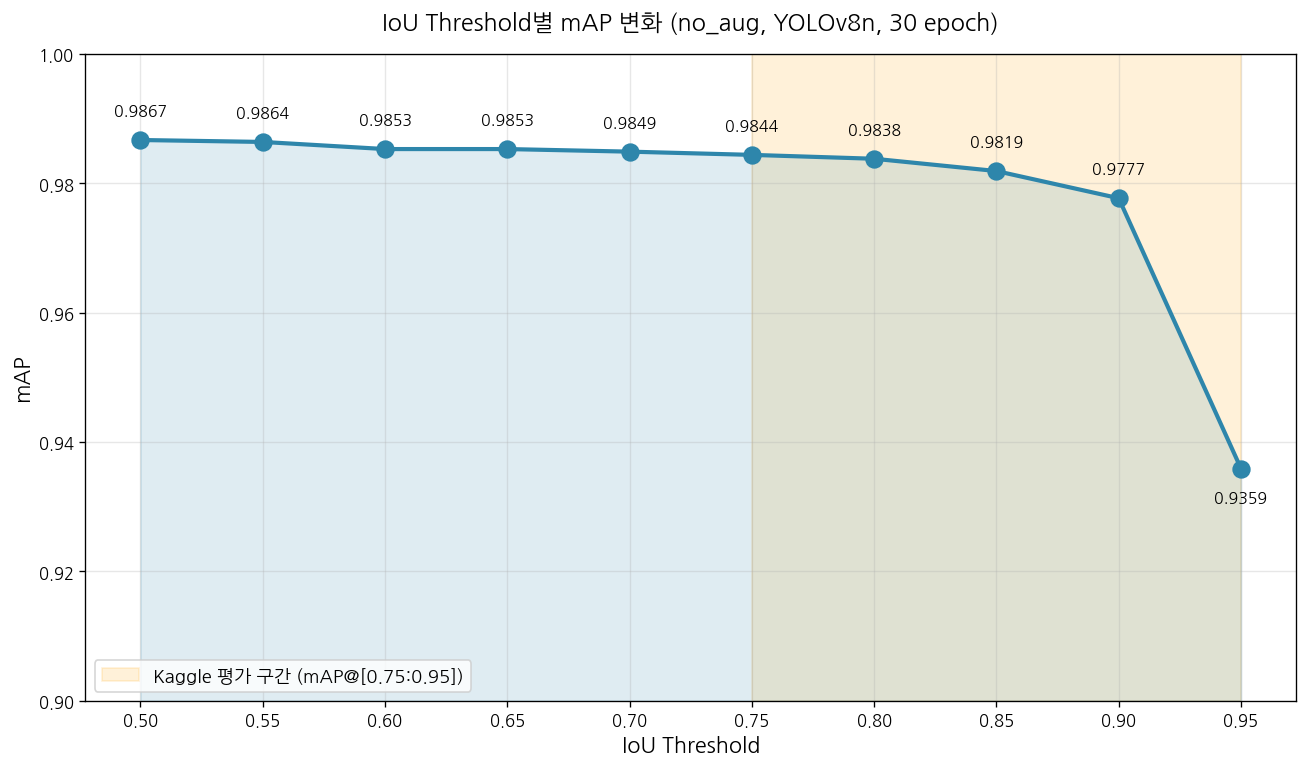

저장: /content/map_by_iou.png


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np

# 한글 폰트 설정 (Drive에 NanumGothic.ttf 있음, 확인됨)
font_path = '/content/drive/MyDrive/NanumGothic.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

# 수치 (이미 확보한 10개 포인트)
iou_range = np.array([0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95])
map_per_iou = np.array([0.9867, 0.9864, 0.9853, 0.9853, 0.9849,
                         0.9844, 0.9838, 0.9819, 0.9777, 0.9359])

fig, ax = plt.subplots(figsize=(11, 6.5), dpi=120)

# Kaggle 평가 구간 하이라이트
ax.axvspan(0.75, 0.95, alpha=0.15, color='orange',
           label='Kaggle 평가 구간 (mAP@[0.75:0.95])')

# 메인 라인
ax.plot(iou_range, map_per_iou, marker='o', linewidth=2.5,
        markersize=10, color='#2E86AB', zorder=3)
ax.fill_between(iou_range, map_per_iou, 0.9, alpha=0.15, color='#2E86AB')

# 수치 라벨
for x, y in zip(iou_range, map_per_iou):
    offset = 15 if y > 0.95 else -20
    ax.annotate(f'{y:.4f}', (x, y), textcoords="offset points",
                xytext=(0, offset), ha='center', fontsize=9.5,
                fontweight='bold')

ax.set_xlabel('IoU Threshold', fontsize=13)
ax.set_ylabel('mAP', fontsize=13)
ax.set_title('IoU Threshold별 mAP 변화 (no_aug, YOLOv8n, 30 epoch)',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(iou_range)
ax.set_ylim(0.90, 1.00)
ax.grid(True, alpha=0.3)
ax.legend(loc='lower left', fontsize=11)

plt.tight_layout()
plt.savefig('/content/map_by_iou.png', dpi=150, bbox_inches='tight')
plt.show()
print("저장: /content/map_by_iou.png")